# Telecom Customer Churn Prediction

## Business Problem

A telecom company is facing a serious issue with customer churn.

When a customer leaves the company, the company loses revenue and must spend additional money to acquire a new customer.

The objective of this project is to build a Machine Learning model that can identify customers who are likely to leave the company.

This will help the company provide proactive retention offers to high-risk customers.

## Machine Learning Problem

This is a **Binary Classification problem** because the target variable has two possible outcomes:

* Churn = Yes
* Churn = No

We will use **Logistic Regression** because it can estimate the probability of a customer leaving the company.


## Import Required Libraries

We first import the Python libraries required for data analysis, preprocessing, model building, prediction, and evaluation.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

## Load the Dataset

The telecom customer dataset is loaded using Pandas.

Each row represents one customer and the columns contain customer details such as contract type, tenure, internet service, charges, and churn status.


In [2]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Understand the Dataset

We check the number of rows and columns available in the dataset.

In [3]:
df.shape

(7043, 21)

In [4]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

## Check Data Types

We check the datatype of each column to understand which variables are numerical and which are categorical.

In [5]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## Data Cleaning

The `TotalCharges` column is stored as text.

We convert it into numerical format so that it can be used by the Machine Learning model.

Invalid or blank values are converted into missing values.


In [7]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

In [8]:
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

There are 11 missing values in TotalCharges.

We will handle these missing values during preprocessing using the median.

## Check Target Variable

The target variable is `Churn`.

We check how many customers stayed with the company and how many left.

In [9]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [10]:
df["Churn"].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

## Feature Selection

The customer ID does not provide meaningful information for predicting churn.

Therefore, we remove `customerID`.

The remaining customer attributes are used as input features.

The target variable is `Churn`.


In [11]:
X = df.drop(columns=["customerID", "Churn"])

y = df["Churn"]

## Convert Target Variable

Machine Learning models work better with numerical target values.

Therefore:

* No = 0
* Yes = 1

In [12]:
y = y.map({
    "No": 0,
    "Yes": 1
})

## Identify Feature Types

The dataset contains both numerical and categorical variables.

Numerical variables are processed differently from categorical variables.

In [13]:
numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## Train-Test Split

The dataset is divided into:

* 80% Training Data
* 20% Testing Data

The training data is used to train the model.

The testing data is used to evaluate the model on unseen customer records.

`stratify=y` is used so that the churn distribution remains similar in both training and testing datasets.


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [15]:
print("Training Records:", X_train.shape[0])
print("Testing Records:", X_test.shape[0])

Training Records: 5634
Testing Records: 1409


## Numerical Feature Preprocessing

For numerical variables:

* Missing values are filled using the median.
* StandardScaler is used to standardize numerical values.

In [16]:
numerical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

## Categorical Feature Preprocessing

Categorical variables contain text values such as:

* Male / Female
* Yes / No
* Month-to-month / One year / Two year

Machine Learning models cannot directly understand these text values.

Therefore, One-Hot Encoding is used to convert them into numerical form.

In [17]:
categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

In [18]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numerical_pipeline,
            numerical_features
        ),
        (
            "cat",
            categorical_pipeline,
            categorical_features
        )
    ]
)

## Build the Churn Prediction Model

We use **Logistic Regression** for this project.

Logistic Regression is suitable because the target variable has two possible outcomes:

* 0 = Stay
* 1 = Churn

The model also provides a probability value representing how likely a customer is to churn.

In [19]:
model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            LogisticRegression(max_iter=1000)
        )
    ]
)

## Train the Model

The Logistic Regression model is trained using historical customer data.

In [20]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainde

## Predict Churn Probability

The model estimates the probability that each customer will churn.

A probability close to 1 means the customer has a higher chance of leaving.

A probability close to 0 means the customer is more likely to stay.

In [21]:
y_probability = model.predict_proba(X_test)[:, 1]

## Classify Customers

A default probability threshold of `0.5` is used.

If churn probability is greater than or equal to 0.5:

* Customer is classified as Likely to Churn

Otherwise:

* Customer is classified as Likely to Stay

In [22]:
y_pred = (y_probability >= 0.5).astype(int)

In [23]:
prediction_results = pd.DataFrame({
    "Actual_Churn": y_test.values,
    "Predicted_Churn": y_pred,
    "Churn_Probability": y_probability
})

prediction_results.head()

,Actual_Churn,Predicted_Churn,Churn_Probability
0,0,0,0.045294
1,0,1,0.684411
2,0,0,0.058721
3,0,0,0.401704
4,0,0,0.021548


In [24]:
prediction_results["Actual_Status"] = prediction_results[
    "Actual_Churn"
].map({
    0: "Stay",
    1: "Churn"
})

prediction_results["Predicted_Status"] = prediction_results[
    "Predicted_Churn"
].map({
    0: "Likely to Stay",
    1: "Likely to Churn"
})

prediction_results.head()

,Actual_Churn,Predicted_Churn,Churn_Probability,Actual_Status,Predicted_Status
0,0,0,0.045294,Stay,Likely to Stay
1,0,1,0.684411,Stay,Likely to Churn
2,0,0,0.058721,Stay,Likely to Stay
3,0,0,0.401704,Stay,Likely to Stay
4,0,0,0.021548,Stay,Likely to Stay


## Model Evaluation

The model is evaluated using:

* Accuracy
* Precision
* Recall
* F1 Score
* ROC-AUC Score

These metrics help us understand how well the model identifies churn customers.

In [25]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_probability)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)
print("ROC-AUC:", roc_auc)

Accuracy: 0.8055358410220014
Precision: 0.6572327044025157
Recall: 0.5588235294117647
F1 Score: 0.6040462427745664
ROC-AUC: 0.8418610659019866


## Interpretation of Model Performance

### Accuracy

The model correctly classified approximately **80.6% of customers**.

### Precision

Among customers predicted as churn, approximately **65.7% actually churned**.

### Recall

The model correctly identified approximately **55.9% of all customers who actually churned**.

### F1 Score

The F1 Score is approximately **60.4%**, which balances Precision and Recall.

### ROC-AUC

The ROC-AUC score is approximately **0.842**, indicating that the model has good ability to distinguish churn customers from non-churn customers.

In [26]:
print(
    classification_report(
        y_test,
        y_pred
    )
)

              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



## Confusion Matrix

The Confusion Matrix helps us understand what types of predictions the model made.

It contains:

* True Negative
* False Positive
* False Negative
* True Positive

In [27]:
cm = confusion_matrix(
    y_test,
    y_pred
)

print(cm)

[[926 109]
 [165 209]]


In [28]:
tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

True Negatives: 926
False Positives: 109
False Negatives: 165
True Positives: 209


## How Many Churn Customers Were Correctly Identified?

The number of customers who actually churned and were correctly predicted as churn is represented by the **True Positive value**.

### Result

**209 churn customers were correctly identified.**

These customers can be targeted by the company with retention offers before they leave.

## How Many Non-Churn Customers Were Misclassified?

The number of customers who were actually loyal but were incorrectly predicted as churn is represented by the **False Positive value**.

### Result

**109 loyal customers were incorrectly classified as likely to churn.**

The company may provide unnecessary retention offers to these customers.

## Missed Churn Customers

The model failed to identify **165 customers who actually churned**.

These are False Negatives.

This is important because these customers may leave without receiving any retention action from the company.

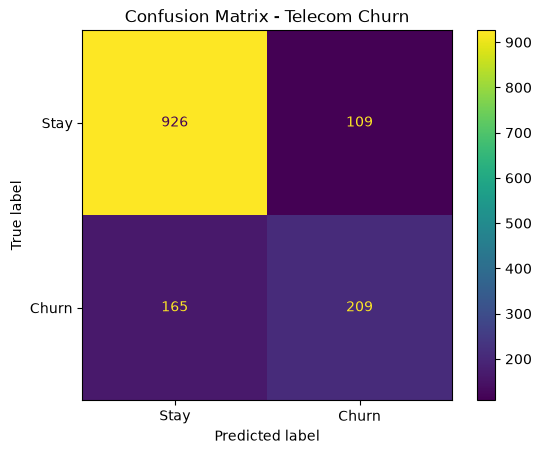

In [29]:
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stay", "Churn"]
).plot()

plt.title("Confusion Matrix - Telecom Churn")
plt.show()

## Predict Churn for an Unseen Customer

We can use the trained model to predict whether a completely new customer is likely to churn.

The following is an example customer record.

In [30]:
new_customer = pd.DataFrame({
    "gender": ["Female"],
    "SeniorCitizen": [0],
    "Partner": ["No"],
    "Dependents": ["No"],
    "tenure": [5],
    "PhoneService": ["Yes"],
    "MultipleLines": ["No"],
    "InternetService": ["Fiber optic"],
    "OnlineSecurity": ["No"],
    "OnlineBackup": ["No"],
    "DeviceProtection": ["No"],
    "TechSupport": ["No"],
    "StreamingTV": ["Yes"],
    "StreamingMovies": ["Yes"],
    "Contract": ["Month-to-month"],
    "PaperlessBilling": ["Yes"],
    "PaymentMethod": ["Electronic check"],
    "MonthlyCharges": [85.0],
    "TotalCharges": [425.0]
})

In [31]:
churn_probability = model.predict_proba(
    new_customer
)[0][1]

print(
    "Churn Probability:",
    churn_probability
)

Churn Probability: 0.7818143674000345


In [32]:
prediction = model.predict(
    new_customer
)[0]

if prediction == 1:
    print("Likely to Churn")
else:
    print("Likely to Stay")

Likely to Churn


## Business Interpretation

In a customer churn problem, both prediction mistakes have different business impacts.

### False Positive

A loyal customer is incorrectly predicted as churn.

In this case, the company may provide a retention discount or special offer even though the customer was not planning to leave.

The company may lose a small amount of money because of an unnecessary offer.

### False Negative

A customer who is actually going to churn is predicted as likely to stay.

This is more serious because the company may take no action and the customer may leave.

The company then loses future revenue and may also need to spend additional money to acquire a new customer.

## Which Mistake Is Better for the Business?

For this telecom churn problem, it is generally better to **wrongly flag a loyal customer as churn** than to miss a customer who is actually going to leave.

In simple terms:

**False Positive is usually less costly than False Negative.**

Giving a retention offer to a loyal customer may cost the company a small amount.

But failing to identify a real churn customer can result in losing the customer completely.

Therefore, the company should focus more on improving **Recall for the churn class**.

## Why Recall Is Important

Recall tells us:

> Out of all customers who actually churned, how many did the model correctly identify?

The current model Recall is approximately:

**55.9%**

This means the model detects only about 56 out of every 100 actual churn customers.

Therefore, improving Recall should be an important goal.

## Suggested Improvement

One improvement is to **adjust the classification threshold**.

Currently, the model uses a threshold of `0.5`.

For example:

* Probability >= 0.5 → Churn
* Probability < 0.5 → Stay

Since missing an actual churn customer is costly, we can reduce the threshold to something like `0.4`.

This can help identify more churn customers and improve Recall.

However, it may also increase False Positives.

Therefore, the threshold should be selected based on the company's business cost and retention strategy.

In [33]:
new_threshold = 0.40

y_pred_40 = (
    y_probability >= new_threshold
).astype(int)

In [34]:
print(
    classification_report(
        y_test,
        y_pred_40
    )
)

              precision    recall  f1-score   support

           0       0.87      0.82      0.84      1035
           1       0.57      0.67      0.62       374

    accuracy                           0.78      1409
   macro avg       0.72      0.74      0.73      1409
weighted avg       0.79      0.78      0.78      1409



## Conclusion

A Logistic Regression model was built to predict telecom customer churn.

The model achieved an accuracy of approximately **80.6%** and a ROC-AUC score of approximately **84.2%**.

The confusion matrix showed that:

* 926 loyal customers were correctly identified.
* 209 churn customers were correctly identified.
* 109 loyal customers were incorrectly classified as churn.
* 165 actual churn customers were missed.

From a business perspective, missing an actual churn customer is usually more costly than wrongly flagging a loyal customer.

Therefore, the company should focus on improving Recall so that more high-risk customers can be identified early and targeted with suitable retention offers.

One possible improvement is to adjust the classification threshold or compare Logistic Regression with models such as Random Forest or Gradient Boosting.